## Objective

Predict if a customer is happy or not based on the answers they give to questions asked.
1. Reach 73% accuracy score or above, or convince us why your solution is superior. We are definitely interested in every solution and insight you can provide us.
    
2. Using a feature selection approach show us understand what is the minimal set of attributes/features that would preserve the most information about the problem while increasing predictability of the data we have.  Is there any question that we can remove in our next survey?

## Setup and data loading

### Imports and settings

In [107]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

RANDOM_STATE = 201

### File paths

In [108]:
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "ACME-HappinessSurvey2020.csv"

### Load and preview the data

In [109]:
raw_df = pd.read_csv(RAW_DATA_PATH)

print(f"Rows: {raw_df.shape[0]}")
print(f"Columns: {raw_df.shape[1]}")

raw_df.head()

Rows: 126
Columns: 7


,Y,X1,X2,X3,X4,X5,X6
0,0,3,3,3,4,2,4
1,0,3,2,3,5,4,3
2,1,5,3,3,3,3,5
3,0,5,4,3,3,3,5
4,0,5,4,3,3,3,5


## Data quality checks

- Y = target attribute (Y) with values indicating 0 (unhappy) and 1 (happy) customers
- X1 = my order was delivered on time
- X2 = contents of my order was as I expected
- X3 = I ordered everything I wanted to order
- X4 = I paid a good price for my order
- X5 = I am satisfied with my courier
- X6 = the app makes ordering easy for me

Attributes X1 to X6 indicate the responses for each question and have values from 1 to 5 where the smaller number indicates less and the higher number indicates more towards the answer.

### Expected columns and data types

In [110]:
TARGET_COLUMN = "Y"
FEATURE_COLUMNS = ["X1", "X2", "X3", "X4", "X5", "X6"]

expected_columns = [TARGET_COLUMN, *FEATURE_COLUMNS]

assert not raw_df.empty, "The dataset is empty."
assert raw_df.columns.is_unique, "Column names are not unique."
assert set(raw_df.columns) == set(expected_columns), "Unexpected or missing columns."

raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 126 entries, 0 to 125
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Y       126 non-null    int64
 1   X1      126 non-null    int64
 2   X2      126 non-null    int64
 3   X3      126 non-null    int64
 4   X4      126 non-null    int64
 5   X5      126 non-null    int64
 6   X6      126 non-null    int64
dtypes: int64(7)
memory usage: 7.0 KB


### Missing values and unique value counts

In [111]:
quality_summary = pd.DataFrame(
    {
        "dtype": raw_df.dtypes,
        "missing_count": raw_df.isna().sum(),
        "missing_pct": raw_df.isna().mean().mul(100).round(1),
        "unique_count": raw_df.nunique(),
    }
)

quality_summary

,dtype,missing_count,missing_pct,unique_count
Y,int64,0,0.0,2
X1,int64,0,0.0,4
X2,int64,0,0.0,5
X3,int64,0,0.0,5
X4,int64,0,0.0,5
X5,int64,0,0.0,5
X6,int64,0,0.0,5


### Values outside the allowed sets

In [112]:
allowed_values = {column: [1, 2, 3, 4, 5] for column in FEATURE_COLUMNS}
allowed_values[TARGET_COLUMN] = [0, 1]

invalid_counts = {}

for column in expected_columns:
    values = raw_df[column]
    invalid_counts[column] = (~values.isin(allowed_values[column])).sum()

pd.Series(invalid_counts, name="invalid_count")

Y     0
X1    0
X2    0
X3    0
X4    0
X5    0
X6    0
Name: invalid_count, dtype: int64

### Repeated rows and answer patterns

An **answer pattern** is one complete combination of scores across X1–X6.
A pattern repeats when at least two rows share those six scores.

The table includes every repeated answer pattern:

- **row_count:** Number of original rows with that pattern.
- **target_count:** Number of distinct happiness labels within that pattern.
  A value of 1 means all labels agree. A value of 2 means both labels occur.

In [113]:
profile_summary = (
    raw_df.groupby(FEATURE_COLUMNS, dropna=False)
    .agg(
        row_count=(TARGET_COLUMN, "size"),
        target_count=(TARGET_COLUMN, "nunique"),
    )
    .reset_index()
)

repeated_answer_patterns = (
    profile_summary.loc[profile_summary["row_count"].gt(1)]
    .sort_values("target_count", ascending=False)
    .reset_index(drop=True)
)

print(f"Exact duplicate rows beyond the first occurrence: {raw_df.duplicated().sum()}")
print(f"Answer patterns that occur at least twice: {len(repeated_answer_patterns)}")
print(
    "Repeated answer patterns with both target labels: "
    f"{repeated_answer_patterns['target_count'].gt(1).sum()}"
)

print("\nRepeated Answer Patterns")

display(repeated_answer_patterns)

Exact duplicate rows beyond the first occurrence: 16
Answer patterns that occur at least twice: 19
Repeated answer patterns with both target labels: 7

Repeated Answer Patterns


,X1,X2,X3,X4,X5,X6,row_count,target_count
0,4,3,3,4,2,4,2,2
1,4,2,4,4,4,4,3,2
2,4,2,3,3,4,4,2,2
3,5,3,3,3,5,3,2,2
4,5,3,3,4,4,5,3,2
5,5,2,4,4,5,5,3,2
6,5,2,3,3,2,5,2,2
7,4,1,3,4,4,4,2,1
8,3,3,1,3,3,4,2,1
9,3,2,4,4,4,5,2,1


## Data split and EDA

**Problems:** 
- Seven repeated answer patterns contain both happiness labels (target_count = 2). For a given pattern, the training data may contain only one label. A model that learns that association will misclassify identical test responses with the opposite label. How these responses fall across the split can therefore affect measured accuracy.
- An 80/20 train/test split leaves 100 training responses and 26 test responses.  One additional correct prediction changes test accuracy by about 3.85 percentage points (100 / 26).  A few different predictions can therefore change the reported accuracy substantially.

**Attempted Solution:**
- Use all 126 responses in repeated nested cross-validation. Each outer fold holds out responses for evaluation. There is no permanent test set.


### Define features and target

In [114]:
# They now contain all responses, with no permanent test set.
X_train = raw_df[FEATURE_COLUMNS].copy()
y_train = raw_df[TARGET_COLUMN].copy()
train_df = X_train.join(y_train)

print(f"Responses available for nested cross-validation: {len(X_train)}")

Responses available for nested cross-validation: 126


### Check the training class balance

In [115]:
target_summary = (
    y_train.value_counts()
    .reindex([0, 1])
    .to_frame("count")
)

target_summary["percentage"] = (
    target_summary["count"].div(len(y_train)).mul(100).round(1)
)

target_summary

,count,percentage
Y,,
0,57,45.2
1,69,54.8


### Explore survey scores by happiness label

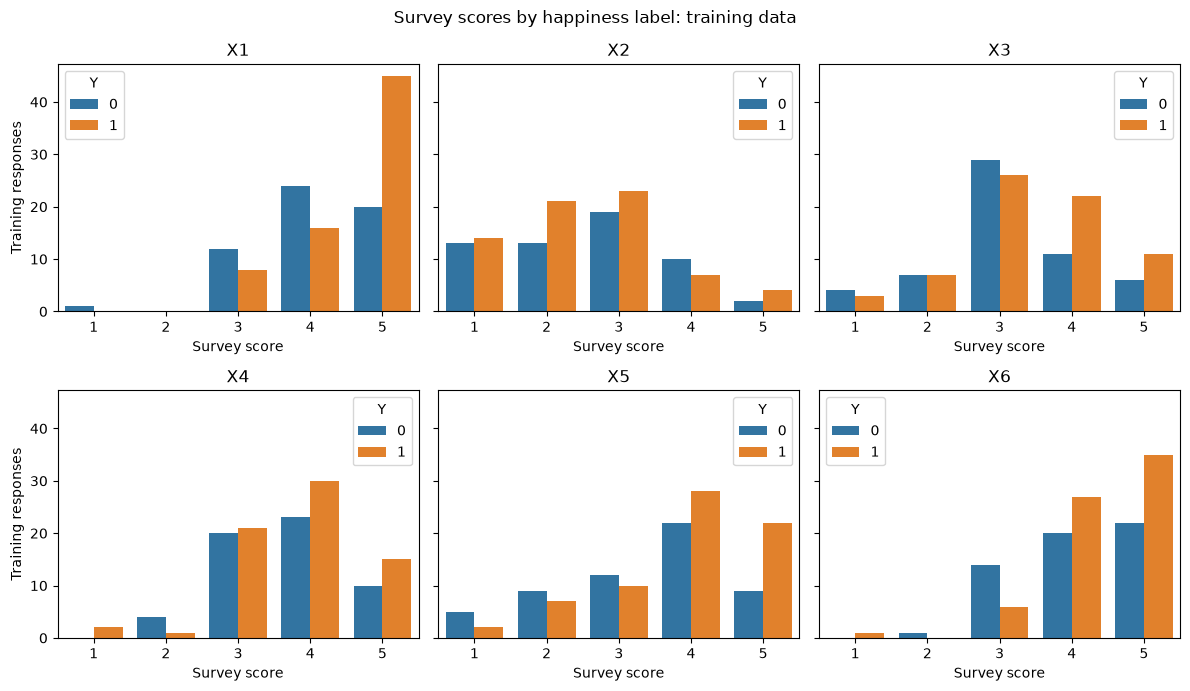

In [116]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharey=True)

for column, ax in zip(FEATURE_COLUMNS, axes.flat):
    sns.countplot(
        data=train_df,
        x=column,
        hue=TARGET_COLUMN,
        order=[1, 2, 3, 4, 5],
        hue_order=[0, 1],
        ax=ax,
    )
    ax.set_title(column)
    ax.set_xlabel("Survey score")
    ax.set_ylabel("Training responses")

fig.suptitle("Survey scores by happiness label: training data")
fig.tight_layout()
plt.show()

- Y = target attribute (Y) with values indicating 0 (unhappy) and 1 (happy) customers
- X1 = my order was delivered on time
- X2 = contents of my order was as I expected
- X3 = I ordered everything I wanted to order
- X4 = I paid a good price for my order
- X5 = I am satisfied with my courier
- X6 = the app makes ordering easy for me

Attributes X1 to X6 indicate the responses for each question and have values from 1 to 5 where the smaller number indicates less and the higher number indicates more towards the answer.1

### Examine correlations

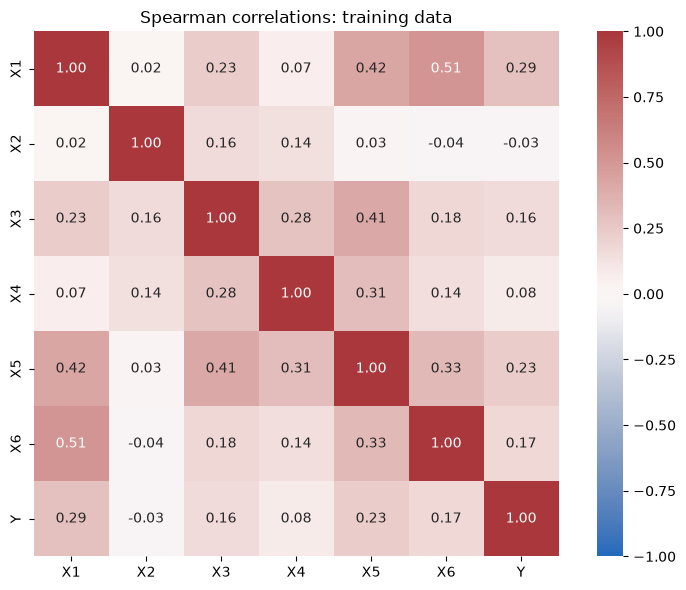

In [117]:
spearman_corr = train_df[
    [*FEATURE_COLUMNS, TARGET_COLUMN]
].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    cmap="vlag",
    square=True,
    ax=ax,
)

ax.set_title("Spearman correlations: training data")
fig.tight_layout()
plt.show()

## Baseline and model comparison

Use five-fold stratified outer cross-validation, repeated ten times.

Within each outer training fold, use five-fold stratified cross-validation
to select the model family and number of questions.

SelectKBest ranks questions using their individual association with happiness.

Compare three procedures on the same outer folds:
- Model selection with feature selection.
- Model selection using all six questions.
- A majority-class baseline.

Combine the held-out predictions within each repetition.
Report mean accuracy, mean balanced accuracy, and the standard deviation
of accuracy across repetitions. This standard deviation measures sensitivity
to the splits; it is not a confidence interval.

1. Split the responses into five outer folds.
2. Hold one fold aside. Use five-fold inner CV on the other four folds to choose the model and question count.
3. Refit the chosen pipeline on those four outer folds. Predict the held-out fold.
4. Repeat until every response has one held-out prediction. This completes one repetition.
5. Repeat the whole process ten times with different splits.

### Imports

In [118]:
import numpy as np
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import (
    GridSearchCV,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

### Validation splits, scoring, models, and parameter searches

In [119]:
N_SPLITS = 5
N_REPEATS = 10

cv = RepeatedStratifiedKFold(
    n_splits=N_SPLITS,
    n_repeats=N_REPEATS,
    random_state=RANDOM_STATE,
)
cv_splits = list(cv.split(X_train, y_train))

inner_cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
}

pipeline = Pipeline(
    [
        ("select", SelectKBest(score_func=f_classif)),
        ("scale", "passthrough"),
        ("model", LogisticRegression()),
    ]
)

question_counts = list(range(1, X_train.shape[1] + 1))

param_grid = [
    {
        "select__k": question_counts,
        "scale": [StandardScaler()],
        "model": [LogisticRegression()],
    },
    {
        "select__k": question_counts,
        "scale": ["passthrough"],
        "model": [DecisionTreeClassifier(random_state=RANDOM_STATE)],
    },
    {
        "select__k": question_counts,
        "scale": ["passthrough"],
        "model": [RandomForestClassifier(random_state=RANDOM_STATE)],
    },
]

search = GridSearchCV(
    pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=inner_cv,
    refit=True,
    n_jobs=-1,
    error_score="raise",
)

# Compare feature selection with keeping every question.
all_questions_grid = [
    {**grid, "select__k": [X_train.shape[1]]}
    for grid in param_grid
]

models = {
    "Model selection": search,
    "All questions": clone(search).set_params(param_grid=all_questions_grid),
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
}

### Train, tune, and compare

In [120]:
cv_results = {}
repeat_rows = []
comparison_rows = []

for name, model in models.items():
    print(f"Evaluating {name}...", flush=True)

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv_splits,
        scoring=scoring,
        return_train_score=True,
        return_estimator=True,
        error_score="raise",
    )
    cv_results[name] = scores

    # Combine the five held-out folds within each repetition.
    repeat_predictions = np.empty((N_REPEATS, len(y_train)), dtype=int)

    for split_index, ((_, test_index), fitted_model) in enumerate(
        zip(cv_splits, scores["estimator"])
    ):
        repeat = split_index // N_SPLITS
        repeat_predictions[repeat, test_index] = fitted_model.predict(
            X_train.iloc[test_index]
        )

    accuracies = []
    balanced_accuracies = []

    for repeat, predictions in enumerate(repeat_predictions, start=1):
        accuracy = accuracy_score(y_train, predictions)
        balanced_accuracy = balanced_accuracy_score(y_train, predictions)

        accuracies.append(accuracy)
        balanced_accuracies.append(balanced_accuracy)
        repeat_rows.append(
            {
                "procedure": name,
                "repeat": repeat,
                "accuracy": accuracy,
                "balanced_accuracy": balanced_accuracy,
            }
        )

    comparison_rows.append(
        {
            "procedure": name,
            "train_accuracy": scores["train_accuracy"].mean(),
            "cv_accuracy": np.mean(accuracies),
            "repeat_accuracy_sd": np.std(accuracies, ddof=1),
            "cv_balanced_accuracy": np.mean(balanced_accuracies),
        }
    )

repeat_results = pd.DataFrame(repeat_rows)
comparison = pd.DataFrame(comparison_rows).set_index("procedure")

baseline_accuracy = comparison.loc["Majority baseline", "cv_accuracy"]
comparison["gain_vs_baseline_pp"] = (
    comparison["cv_accuracy"] - baseline_accuracy
).mul(100)

display(comparison.round(3))
display(
    repeat_results.pivot(
        index="repeat",
        columns="procedure",
        values="accuracy",
    ).round(3)
)

Evaluating Model selection...
Evaluating All questions...
Evaluating Majority baseline...


,train_accuracy,cv_accuracy,repeat_accuracy_sd,cv_balanced_accuracy,gain_vs_baseline_pp
procedure,,,,,
Model selection,0.772,0.609,0.035,0.603,6.111
All questions,0.826,0.547,0.035,0.536,-0.079
Majority baseline,0.548,0.548,0.000,0.500,0.000


procedure,All questions,Majority baseline,Model selection
repeat,,,
1,0.548,0.548,0.611
2,0.484,0.548,0.603
3,0.532,0.548,0.619
4,0.587,0.548,0.643
5,0.579,0.548,0.611
6,0.532,0.548,0.548
7,0.579,0.548,0.659
8,0.516,0.548,0.571
9,0.524,0.548,0.579


### Inspect the selected models

In [121]:
selected_models = pd.Series(
    [
        type(fitted_search.best_estimator_.named_steps["model"]).__name__
        for fitted_search in cv_results["Model selection"]["estimator"]
    ],
    name="model",
)

selection_counts = (
    selected_models.value_counts()
    .rename("outer_folds")
    .to_frame()
)

display(selection_counts)

,outer_folds
model,
RandomForestClassifier,24
DecisionTreeClassifier,22
LogisticRegression,4


## Fit the final model 

- Run the same model selection search on all 126 responses. Refit the selected model on all responses and retain its pipeline as final_model.

- Report the repeated nested cross-validation results as an internal estimate of the selection procedure's performance. The reported standard deviation measures split sensitivity,  not a confidence interval. Fitting the final model does not produce a separate test score.

In [122]:
final_search = clone(search)
final_search.fit(X_train, y_train)

final_model = final_search.best_estimator_
selected_name = type(final_model.named_steps["model"]).__name__

selected_mask = final_model.named_steps["select"].get_support()
selected_questions = X_train.columns[selected_mask].tolist()
omitted_questions = X_train.columns[~selected_mask].tolist()

print(f"Final model: {selected_name}")
print(f"Selected questions: {selected_questions}")
print(f"Omitted questions: {omitted_questions}")
print(f"Responses used for final fitting: {len(y_train)}")

print("\nSelected search settings:")
display(final_search.best_params_)

print("\nNested CV results for the evaluated procedures:")
display(comparison.round(3))

Final model: RandomForestClassifier
Selected questions: ['X1', 'X5', 'X6']
Omitted questions: ['X2', 'X3', 'X4']
Responses used for final fitting: 126

Selected search settings:


{'model': RandomForestClassifier(random_state=201),
 'scale': 'passthrough',
 'select__k': 3}


Nested CV results for the evaluated procedures:


,train_accuracy,cv_accuracy,repeat_accuracy_sd,cv_balanced_accuracy,gain_vs_baseline_pp
procedure,,,,,
Model selection,0.772,0.609,0.035,0.603,6.111
All questions,0.826,0.547,0.035,0.536,-0.079
Majority baseline,0.548,0.548,0.000,0.500,0.000


## Explain the final model with SHAP

Use SHAP to describe how the fitted pipeline uses the survey questions.

Feature selection is evaluated through nested cross-validation above.
The SHAP values explain the final fitted model; they do not establish
that removing a question preserves predictive performance.

Background dataset has 126 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=126 when initializing the masker.


,mean_absolute_shap
X1,0.1821
X6,0.1143
X5,0.0635
X2,0.0000
X3,0.0000
X4,0.0000


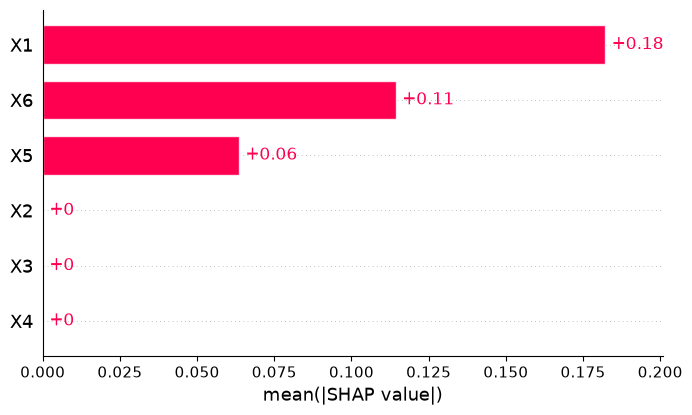

In [123]:
import shap

def predict_happiness(data):
    data = pd.DataFrame(data, columns=X_train.columns)
    return final_model.predict_proba(data)[:, 1]

explainer = shap.Explainer(predict_happiness, X_train)
shap_values = explainer(X_train)

question_importance = pd.Series(
    np.abs(shap_values.values).mean(axis=0),
    index=X_train.columns,
    name="mean_absolute_shap",
).sort_values(ascending=False)

display(question_importance.to_frame().round(4))
shap.plots.bar(shap_values)